# Neural prices and spot risk

The value-gradient solver fits a shared $u_\theta(t,s)$ and
differentiates it in physical spot units. The terminal-loss solver
learns a free initial value and Brownian controls on the grid.
For the latter, $\Sigma(s_0)^\top\Delta=\widetilde Z_0$ recovers
spot delta from the initial control. Both checkpoints are selected
by their own scheduled validation loss.

## Execution and reference precision

In [1]:
import sys
from pathlib import Path

import numpy as np
from IPython.display import Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import json
from collections import Counter

import matplotlib.pyplot as plt

local_summary = root / "scratch/runs/final_suite/summary.json"
results_path = local_summary if local_summary.is_file() else root / "experiments/results.json"
results = json.loads(results_path.read_text())
design = json.loads((root / "experiments/design.json").read_text())

fits = results["fits"]
names = {"value_gradient": "Value-gradient", "terminal_loss": "Terminal loss"}
base_steps = design["training"]["base_steps"]
base = [fit for fit in fits if fit["job"]["n_steps"] == base_steps]
status = Counter(fit["status"] for fit in fits)
accuracy = Counter(fit.get("accuracy", "unavailable") for fit in fits
                   if fit["status"] == "completed")
reference_status = Counter(row["status"] for row in results["references"].values())
lines = ["| Scope | Outcome | Count |", "| --- | --- | ---: |"]
for scope, counts in (("Fit execution", status), ("Completed-fit accuracy", accuracy),
                      ("Reference", reference_status)):
    lines.extend(f"| {scope} | {label.replace('_', ' ')} | {n} |" for label, n in sorted(counts.items()))
runtime = results["runtime"]
display(Markdown(
    f"Python {runtime['python']}, PyTorch {runtime['torch']}, {runtime['system']}.\n\n"
    + "\n".join(lines)
))
lines = ["| Solver | Price passes | All-delta passes | Joint passes | Fits with a delta bound violation |",
         "| --- | ---: | ---: | ---: | ---: |"]
for solver, name in names.items():
    rows = [r for r in fits if r["job"]["solver"] == solver and r["status"] == "completed"]
    price = sum(r["price_classification"] == "within_target" for r in rows)
    delta = sum(r["delta_classifications"] == {"within_target": len(r["delta"])} for r in rows)
    joint = sum(r.get("accuracy") == "within_target" for r in rows)
    bounds = sum(r["initial_bound_violations"] > 0 for r in rows)
    lines.append(f"| {name} | {price}/{len(rows)} | {delta}/{len(rows)} | {joint}/{len(rows)} "
                 f"| {bounds}/{len(rows)} |")
display(Markdown("\n".join(lines)))

Python 3.12.16, PyTorch 2.15.0, macOS-27.0.1-arm64-arm-64bit.

| Scope | Outcome | Count |
| --- | --- | ---: |
| Fit execution | completed | 78 |
| Completed-fit accuracy | accuracy miss | 77 |
| Completed-fit accuracy | within target | 1 |
| Reference | exact | 2 |
| Reference | usable | 8 |

| Solver | Price passes | All-delta passes | Joint passes | Fits with a delta bound violation |
| --- | ---: | ---: | ---: | ---: |
| Value-gradient | 3/39 | 0/39 | 0/39 | 4/39 |
| Terminal loss | 14/39 | 3/39 | 1/39 | 6/39 |

An accuracy pass requires both an absolute price error at most
$0.01$ and absolute error at most $0.01$ in every $\Delta_i/w_i$,
accounting for the reference interval. All eight arithmetic
references in the retained run qualified at the first allocation.
Their largest price half-width was 0.00056, well within the 0.002
budget. Terminal loss passed the price target more often. Its
recovered deltas also violated an economic bound in more fits.
The bounds check nonnegativity and the case-specific delta ceiling.

## Initial price and coordinate delta errors

Each point below is a completed fit at 16 intervals. The second
panel displays the largest absolute coordinate error within that
fit after dividing by the corresponding asset weight. Point
spread within a case and formulation is the observed seed variation.

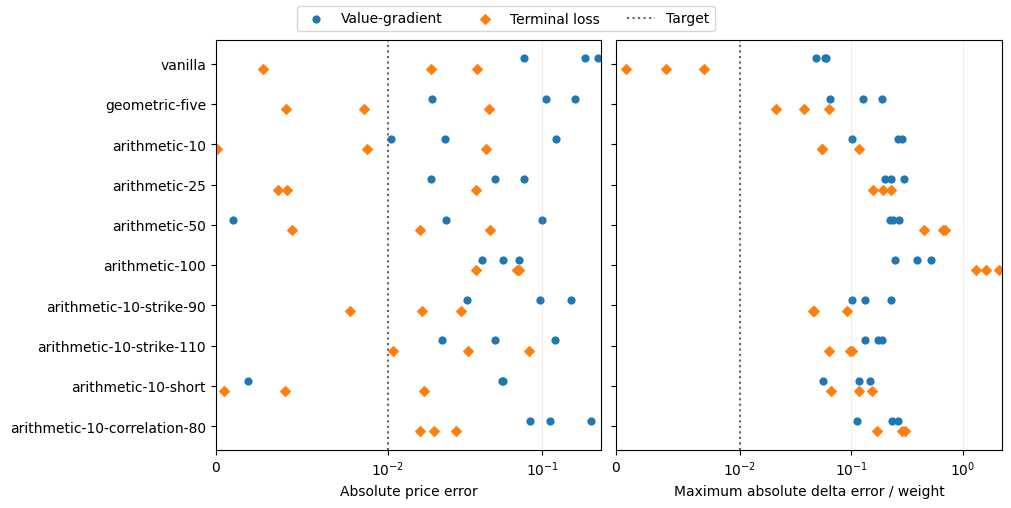

In [2]:
cases = [row["name"] for row in design["cases"]]
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 5), layout="constrained")
for solver, offset, marker in (("value_gradient", -0.13, "o"), ("terminal_loss", 0.13, "D")):
    rows = [r for r in base if r["job"]["solver"] == solver and r["status"] == "completed"
            and r["scaled_delta_errors"] and r.get("accuracy") != "reference_inconclusive"]
    y = [cases.index(r["job"]["case"]) + offset for r in rows]
    axes[0].scatter([abs(r["price_error"]) for r in rows], y, marker=marker, label=names[solver], s=24)
    axes[1].scatter([max(map(abs, r["scaled_delta_errors"])) for r in rows], y, marker=marker, s=24)
for ax, label in zip(axes, ("Absolute price error", "Maximum absolute delta error / weight")):
    ax.axvline(0.01, color="0.4", linestyle=":", label="Target")
    ax.set_xscale("symlog", linthresh=0.01)
    ax.set(xlabel=label, xlim=(0, None))
    ax.grid(axis="x", alpha=0.2)
axes[0].set_yticks(range(len(cases)), labels=cases)
axes[0].invert_yaxis()
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside upper center", ncols=3)
plt.show()

A point left of the line in the price panel can still miss the
joint target because of coordinate delta errors. The formal
classifications also propagate reference uncertainty. The
arithmetic dimension ladder changes diversification along with
dimension because the basket is equally weighted. All six fits
at 100 assets missed the price target. Their absolute price errors
ranged from 0.037 to 0.071.

## Arithmetic time grid

All grids share the same independent reference and the same fit
budget. Ranges below span completed seeds. The joint-pass
column counts fits that passed both locked targets.

In [3]:
lines = ["| Intervals | Solver | Completed / scheduled | Joint passes | Absolute price error | "
         "Worst scaled delta error | Median fit (s) |",
         "| ---: | --- | ---: | ---: | ---: | ---: | ---: |"]
for steps in sorted([base_steps, *design["grid_steps"]]):
    for solver in names:
        rows = [r for r in fits if r["job"]["case"] == design["grid_case"]
                and (r["job"]["n_steps"], r["job"]["solver"]) == (steps, solver)]
        completed = [r for r in rows if r["status"] == "completed"]
        comparable = [r for r in completed if r["price_error"] is not None and r["scaled_delta_errors"]]
        price = [abs(r["price_error"]) for r in comparable]
        delta = [max(map(abs, r["scaled_delta_errors"])) for r in comparable]
        price_range = f"{min(price):.4f}–{max(price):.4f}" if price else "—"
        worst_delta = f"{max(delta):.4f}" if delta else "—"
        seconds = f"{np.median([r['training_seconds'] for r in completed]):.1f}" if completed else "—"
        passes = sum(r.get("accuracy") == "within_target" for r in completed)
        lines.append(f"| {steps} | {names[solver]} | {len(completed)}/{len(rows)} "
                     f"| {passes} | {price_range} | {worst_delta} | {seconds} |")
display(Markdown("\n".join(lines)))

| Intervals | Solver | Completed / scheduled | Joint passes | Absolute price error | Worst scaled delta error | Median fit (s) |
| ---: | --- | ---: | ---: | ---: | ---: | ---: |
| 10 | Value-gradient | 3/3 | 0 | 0.0105–0.1033 | 0.2534 | 7.0 |
| 10 | Terminal loss | 3/3 | 0 | 0.0096–0.0596 | 0.1010 | 10.0 |
| 16 | Value-gradient | 3/3 | 0 | 0.0105–0.1220 | 0.2860 | 9.1 |
| 16 | Terminal loss | 3/3 | 0 | 0.0000–0.0435 | 0.1171 | 16.2 |
| 20 | Value-gradient | 3/3 | 0 | 0.0250–0.1820 | 0.2933 | 11.2 |
| 20 | Terminal loss | 3/3 | 0 | 0.0019–0.0111 | 0.0914 | 20.5 |
| 40 | Value-gradient | 3/3 | 0 | 0.0068–0.1047 | 0.3035 | 21.1 |
| 40 | Terminal loss | 3/3 | 0 | 0.0053–0.0170 | 0.1078 | 42.8 |

The GBM transitions are exact on each grid. Changes in error
therefore reflect the learned approximation and stochastic-integral
discretisation together. The terminal architecture also adds a
network per extra time node. Six of the 24 fits met the price
target. Every fit missed the joint target once coordinate risk
was included. Errors varied non-monotonically across grids.

## Vanilla curvature and held-out paths

The value network defines a differentiable spot-to-price surface.
Compare its initial gamma with Black–Scholes and measure its
pre-expiry price and delta RMSE on a separate set of paths.

In [4]:
lines = ["| Seed | Learned gamma | Exact gamma | Price RMSE | Delta RMSE |",
         "| ---: | ---: | ---: | ---: | ---: |"]
for row in base:
    gamma = row.get("gamma")
    if row["job"]["case"] == "vanilla" and row["status"] == "completed" and gamma:
        error = row["path_rmse"]
        lines.append(f"| {row['job']['seed']} | {gamma['estimate']:.6f} | {gamma['reference']:.6f} "
                     f"| {error['price_rmse_before_expiry']:.4f} | {error['delta_rmse_before_expiry']:.4f} |")
display(Markdown("\n".join(lines)))

| Seed | Learned gamma | Exact gamma | Price RMSE | Delta RMSE |
| ---: | ---: | ---: | ---: | ---: |
| 41001 | 0.004682 | 0.019333 | 0.9233 | 0.1028 |
| 41002 | 0.002828 | 0.019333 | 0.9594 | 0.1100 |
| 41003 | 0.002002 | 0.019333 | 0.9499 | 0.1108 |

The fitted gammas of 0.0020 to 0.0047 substantially understate
the Black–Scholes value of 0.0193. The path RMSEs average over
visited states and pre-expiry times. Each measures a
separate property of the fitted value function. For the terminal
solver, the available spot sensitivities come from control recovery.